# ALHIC2501 · DC-normalized basic plots
Estimate the repeatable transverse DC bias at each distance above scan start, using the highest-Y track at matched depths as the reference. Use six bins of relative track rank and a median across training sections. Subtract the learned relative offset in units of each track’s central current before standard outer-track scaling. Tracks without a usable reference receive only the standard scaling. Gray marks the unreliable deep end.

For each target, compare whole-core and nearest 4, 8, 16 and 32 leave-one-section-out profiles. Use the nearest eight measured DC sections for plotting, allowing earlier and later scans. A slot/depth cell with fewer than three contributing neighbors uses the held-out whole-core estimate. Distances are relative to the measured bottom. The correction targets transverse bias, while common-mode signals remain in plotted DC data.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Patch, Rectangle
from matplotlib.cm import ScalarMappable

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/metadata.csv').exists())
sys.path.insert(0,str(root/'scripts/core_scripts'))
from ECMclass import ECM
data = root/'data'
out = root/'figures/basic_plots_normalized/ALHIC2501'
out.mkdir(parents=True,exist_ok=True)
meta = pd.read_csv(data/'metadata.csv').query("core=='ALHIC2501'").drop_duplicates(['section','face','ACorDC'])
def load(row):
    fname = f'{row.core}-{row.section}-{row.face}-{row.ACorDC}.csv'
    folder = 'clean' if (data/'clean'/row.core/fname).exists() else 'not-cleaned'
    return ECM(row.core,row.section,row.face,row.ACorDC,str(data/folder)+'/',data/'metadata.csv')

In [2]:
# Distance above measured bottom in 1 cm bins. Divide each track by its middle level
# so that high-current sections do not dominate the cross-section template.
rows = []
refs = {}
missing_refs = []
for row in meta.query("ACorDC=='DC'").itertuples():
    scan = load(row)
    dist = scan.depth.max()-scan.depth
    span = np.ptp(scan.depth)
    for i,y in enumerate(scan.y_vec):
        ok = (scan.y==y) & (scan.surface_imperfection==0)
        bins = pd.Series(scan.meas[ok]).groupby(np.floor(dist[ok]*100).astype(int)).median()
        center = (bins.index+.5)/100
        ref = bins[(center>=.35*span)&(center<=.65*span)].median()
        if not np.isfinite(ref) or ref<=0:
            missing_refs.append((row.section,y))
            continue
        refs[row.section,y] = ref
        slot = round(5*i/(len(scan.y_vec)-1))
        rows.append(pd.DataFrame(dict(section=row.section,y=y,slot=slot,bin=bins.index,
                                      relative=bins.values/ref,high=i==len(scan.y_vec)-1,
                                      low=i==0)))
samples = pd.concat(rows,ignore_index=True)
reference = samples[samples.high].set_index(['section','bin']).relative.rename('high_relative')
paired = samples.join(reference,on=['section','bin']).dropna(subset=['high_relative']).copy()
paired['difference'] = paired.relative-paired.high_relative
training = paired[paired.bin.between(3,39)].groupby(['section','slot','bin']).difference.median().reset_index()
print('Tracks receiving only standard outer-track scaling (section, Y in mm):',missing_refs)

Tracks receiving only standard outer-track scaling (section, Y in mm): [('12', 125.702), ('145', 111.77), ('177', 169.857), ('191', 92.165), ('193', 106.115), ('210', 120.461), ('225', 134.269), ('225', 143.769), ('23', 155.911), ('23', 162.506), ('245', 90.955), ('248', 123.558), ('267', 145.906), ('298', 107.296), ('3', 167.787), ('99', 165.734)]


In [3]:
# Reconstruct acquisition order from the DC scans. The target never contributes to its template.
order = meta.query("ACorDC=='DC'").sort_values('time').section.tolist()
nodes = np.r_[.03,np.arange(3,40)/100+.005,.40]
cells = pd.MultiIndex.from_product([range(6),range(3,40)],names=['slot','bin'])
matrix = training.pivot(index='section',columns=['slot','bin'],values='difference').reindex(index=order,columns=cells).to_numpy()
import warnings
def templates_for(k):
    templates = {}
    for i,s in enumerate(order):
        donors = np.delete(np.arange(len(order)),i)
        nearest = donors[np.argsort(np.abs(donors-i),kind='stable')[:k]]
        values = matrix[nearest]
        with warnings.catch_warnings():
            warnings.simplefilter('ignore',RuntimeWarning)
            center = np.nanmedian(values,axis=0)
            # The whole-core profile provides a fallback where nearby scans are sparse.
            global_values = matrix[donors]
            baseline = np.nanmedian(global_values,axis=0)
        baseline[np.isfinite(global_values).sum(axis=0)<15] = np.nan
        support = np.isfinite(values).sum(axis=0)
        minimum = 15 if k is None else max(3,int(np.ceil(k/3)))
        center = np.where(support>=minimum,center,baseline)
        curves = {}
        for slot,v in enumerate(center.reshape(6,37)):
            good = np.isfinite(v)
            smooth = pd.Series(v[good]).rolling(3,center=True,min_periods=1).mean()
            curve = np.interp(nodes,nodes[1:-1][good],smooth)
            curves[slot] = curve*np.clip((.40-nodes)/.05,0,1)
        templates[s] = curves
    return templates
def evaluate(templates):
    test = paired[paired.bin.between(3,39) & ~paired.high].copy()
    test['residual'] = test.difference
    for (s,slot),g in test.groupby(['section','slot']):
        test.loc[g.index,'residual'] -= np.interp((g.bin+.5)/100,nodes,templates[s][slot])
    targeted = test[test.low & test.bin.between(10,19)].groupby('section').residual.mean()*100
    broad = test.assign(error=test.residual.abs()*100).groupby(['section','y']).error.mean().groupby('section').mean()
    return targeted,broad
candidates = [None,4,8,16,32]
fits = {k:templates_for(k) for k in candidates}
scores = {k:evaluate(fits[k]) for k in candidates}
summaries = []
for k,(g,broad) in scores.items():
    last = g.reindex(order[-6:]).dropna()
    summaries.append([g.abs().mean(),g.reindex(order[-20:]).abs().mean(),last.abs().mean(),last.mean(),
                      broad.mean(),broad.reindex(order[-6:]).mean()])
report = pd.DataFrame(summaries,index=['whole',4,8,16,32],columns=['outer all','outer final 20','outer final 6','signed final 6','all tracks','all tracks final 6'])
print(report.round(1).to_string())
print(pd.DataFrame({str(k):v[0].reindex(order[-6:]) for k,v in scores.items()}).round(1))


       outer all  outer final 20  outer final 6  signed final 6  all tracks  all tracks final 6
whole       32.9            41.3           71.0            71.0        24.8                19.8
4           31.7            31.2           33.2            31.9        25.3                14.9
8           31.2            29.9           22.7            22.7        24.3                13.4
16          32.2            35.6           44.1            44.1        24.1                15.4
32          31.8            38.2           58.8            58.8        23.9                18.2
          None     4     8    16     32
section                                
331       55.9  13.5  10.0  29.7   43.8
335       72.2  24.6  22.6  46.0   60.0
339       50.1  -3.9   3.0  29.0   36.5
340       57.5  26.9   7.1  32.6   45.6
333       60.3  33.6  10.2  34.1   48.2
336      130.2  96.8  83.1  93.4  118.9


Mean absolute section gap (percentage points)
All {'Uncorrected': 57.1, 'Whole core': 32.9, 'Nearest eight': 31.2}
Final 20 {'Uncorrected': 42.9, 'Whole core': 41.3, 'Nearest eight': 29.9}
Final six {'Uncorrected': 20.1, 'Whole core': 71.0, 'Nearest eight': 22.7}
Final six in acquisition order, signed gaps:
         Uncorrected  Whole core  Nearest eight
section                                        
331              4.2        55.9           10.0
335             20.5        72.2           22.6
339              2.9        50.1            3.0
340              5.6        57.5            7.1
333              8.7        60.3           10.2
336             78.4       130.2           83.1
0–3 cm, n=148: mean relative to track middle (%) {'High Y': -39.2, 'Interior': -41.1, 'Low Y': -42.4} all three below middle: 114
3–10 cm, n=163: mean relative to track middle (%) {'High Y': -2.2, 'Interior': -18.9, 'Low Y': -27.5} all three below middle: 110
10–20 cm, n=165: mean relative to track middle 

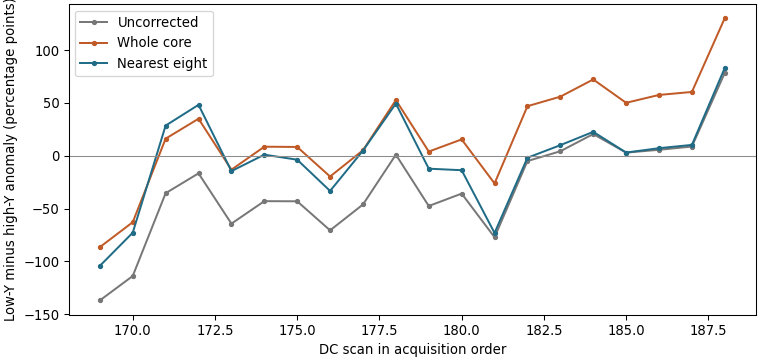

In [4]:
templates = fits[8]
def bias(section,slot,distance):
    return np.interp(distance,nodes,templates[section][slot],left=0,right=0)

raw = paired[paired.low & paired.bin.between(10,19)].groupby('section').difference.mean()*100
gaps = pd.DataFrame({'Uncorrected':raw,'Whole core':scores[None][0],'Nearest eight':scores[8][0]}).reindex(order)
print('Mean absolute section gap (percentage points)')
for label,g in [('All',gaps),('Final 20',gaps.tail(20)),('Final six',gaps.tail(6))]:
    print(label,g.abs().mean().round(1).to_dict())
print('Final six in acquisition order, signed gaps:')
print(gaps.tail(6).round(1).to_string())

# Diagnose an end effect shared by multiple tracks, separately from the side-to-side contrast.
# Use only section/bins with low, interior and high tracks all observed.
sample = paired.assign(side=np.select([paired.low,paired.high],['Low Y','High Y'],default='Interior'))
levels = sample.pivot_table(index=['section','bin'],columns='side',values='relative',aggfunc='median').dropna()
for a,b in [(0,3),(3,10),(10,20),(20,35)]:
    subset = levels[levels.index.get_level_values('bin').isin(range(a,b))]
    section_levels = (subset.groupby('section').mean()-1)*100
    print(f'{a}–{b} cm, n={len(section_levels)}: mean relative to track middle (%)',
          section_levels.mean().round(1).to_dict(),
          'all three below middle:',int(section_levels.lt(0).all(axis=1).sum()))
fig,ax = plt.subplots(figsize=(8,3.8),layout='constrained')
for c,color in zip(gaps,['#777777','#c05a27','#206c86']):
    ax.plot(range(len(order)-19,len(order)+1),gaps[c].tail(20),'.-',label=c,color=color)
ax.axhline(0,color='0.55',lw=.8)
ax.set(xlabel='DC scan in acquisition order',ylabel='Low-Y minus high-Y anomaly (percentage points)')
ax.legend()
fig.savefig(root/'figures/alhic2501_dc/nearby_correction_final_scans.png',dpi=180)
plt.show()


In [5]:
# Evaluate the basic_plots 10 mm moving medians only at the adjacent grid points
# used by the display interpolation. Preserve its 2 mm plotting grid and overlays.
def draw_tracks(ax,scan,norm,bottom):
    window = .010
    first = scan.depth[scan.y==scan.y_vec[0]]
    lo,hi = scan.depth.min()+2*window/3,scan.depth.max()-2*window/3
    grid = np.linspace(lo,hi,int((hi-lo)/abs(np.mean(np.diff(first)))))
    d = np.linspace(round(lo,2),round(hi,2),int((round(hi,2)-round(lo,2))/.002)+1)
    if scan.ACorDC=='DC':
        d = np.r_[d[d<bottom-.03],bottom-.03] if d[-1]>bottom-.03 else d
    indices = np.clip(np.searchsorted(grid,d),1,len(grid)-1)
    need = np.unique(np.r_[indices,indices-1])
    width = np.diff(scan.y_vec)[0]-.2
    for y in scan.y_vec:
        mask = scan.y==y
        order = np.argsort(scan.depth[mask])
        z = scan.depth[mask][order]
        values = np.column_stack([a[mask][order] for a in (scan.meas,scan.surface_imperfection,
                                                         scan.tephra_or_layer,scan.rock_or_debris)])
        left = z.searchsorted(grid[need]-window/2)
        right = z.searchsorted(grid[need]+window/2,side='right')
        meds = np.full((len(need),4),np.nan)
        for size in np.unique(right-left):
            if size>0:
                selected = right-left==size
                meds[selected] = np.median(values[left[selected,None]+np.arange(size)],axis=1)
        current,surface,tephra,rock = [np.interp(d,grid[need],v)[:-1] for v in meds.T]
        x = y-scan.y_left-width/2
        colors = plt.get_cmap('Spectral')(norm(current))
        colors[np.round(surface)!=0] = [0,0,0,1]
        ax.pcolormesh([x,x+width],d,colors[:,None,:],shading='flat',rasterized=True)
        for flag,hatch,color in [(tephra,'xx','purple'),(rock,'oo','black')]:
            changes = np.diff(np.r_[False,np.round(flag)==1,False].astype(int))
            for a,b in zip(np.flatnonzero(changes==1),np.flatnonzero(changes==-1)):
                ax.add_patch(Rectangle((x,d[a]),width,d[b]-d[a],facecolor='none',
                                       edgecolor=color,hatch=hatch,linewidth=0))

def plot_section(section,metadata):
    fig,axes = plt.subplots(1,3,figsize=(9,6),dpi=100,gridspec_kw={'width_ratios':[3,1,3]})
    axes[1].axis('off')
    limits = []
    for ax,channel in zip(axes[::2],['AC','DC']):
        ax.set(xlim=(55,0),ylabel='Depth (m)')
        ax.set_xlabel('Distance From O Line (mm)',fontsize=6)
        r = metadata[metadata.ACorDC==channel]
        if r.empty:
            ax.text(.5,.5,'No DC scan',ha='center',transform=ax.transAxes)
            continue
        scan = load(next(r.itertuples()))
        bottom = scan.depth.max()
        if channel=='DC':
            for i,y in enumerate(scan.y_vec):
                ref = refs.get((section,y))
                if ref is None:
                    continue
                mask = scan.y==y
                slot = round(5*i/(len(scan.y_vec)-1))
                scan.meas[mask] -= ref*bias(section,slot,bottom-scan.depth[mask])
        scan.rem_ends(10)
        if channel=='DC':
            # Exclude the unreliable end from both the outer-track scaling and the color limits.
            keep = scan.depth<=bottom-.03
            for attr in ['depth','meas','y','button','surface_imperfection','tephra_or_layer','rock_or_debris']:
                setattr(scan,attr,getattr(scan,attr)[keep])
        scan.norm_outside()
        norm = Normalize(*np.percentile(scan.meas[scan.button==0],[5,95]))
        draw_tracks(ax,scan,norm,bottom)
        limits.extend([scan.depth.min(),bottom-.01])
        cax = fig.add_axes([.07 if channel=='AC' else .58,-.05,.35,.05])
        fig.colorbar(ScalarMappable(norm=norm,cmap='Spectral'),cax=cax,orientation='horizontal',label='Current (A)')
        if channel=='DC':
            ax.axhspan(bottom-.03,bottom-.01,color='#c6c6c6',zorder=0)
    for ax in axes[::2]:
        ax.set_ylim(max(limits),min(limits))
    fig.suptitle(f'ALHIC2501 section {section}')
    fig.subplots_adjust(left=.085,right=.98,top=.86,bottom=.10,wspace=0)
    for ax,label in zip(axes[::2],['AC','DC · locally normalized']):
        ax.set_title(label,fontweight='bold')
    key = [Patch(color='black',label='Surface Imperfection'),
           Patch(facecolor='none',edgecolor='purple',hatch='xx',label='Tephra/Layer'),
           Patch(facecolor='none',edgecolor='black',hatch='oo',label='Rock/Debris'),
           Patch(color='#c6c6c6',label='DC end excluded')]
    fig.legend(handles=key,loc='center left',bbox_to_anchor=(1,.5),frameon=False)
    fig.savefig(out/f'ALHIC2501-{section}.png',bbox_inches='tight')
    plt.close(fig)

In [6]:
for section, metadata in meta.groupby('section',sort=False):
    plot_section(section,metadata)
print(f'{meta.section.nunique()} section plots in {out}')
from PIL import Image
expected = {f'ALHIC2501-{s}.png' for s in meta.section.unique()}
assert {p.name for p in out.glob('*.png')} == expected
for name in expected:
    with Image.open(out/name) as image:
        image.verify()


189 section plots in /Users/Liam/Desktop/UW/ECM/COLDEX_ECM/COLDEX-ECM-data/figures/basic_plots_normalized/ALHIC2501
